In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from data.fetcher import TickData

tickdata = TickData()

In [3]:
# tickdata.fetch_binance("2024-12-25", "2025-01-05", 'spot', 'PEPEUSDT')
# tickdata.fetch_binance("2024-12-25", "2025-01-05", 'future', '1000PEPEUSDT')

tickdata.fetch_okx("2024-12-25", "2025-01-05", 'spot', 'PEPE-USDT')
tickdata.fetch_okx("2024-12-25", "2025-01-05", 'future', 'PEPE-USDT-SWAP')

[1/12] Fetching Data from PEPE-USDT-trades-2024-12-25.zip...
[2/12] Fetching Data from PEPE-USDT-trades-2024-12-26.zip...
[3/12] Fetching Data from PEPE-USDT-trades-2024-12-27.zip...
[4/12] Fetching Data from PEPE-USDT-trades-2024-12-28.zip...
[5/12] Fetching Data from PEPE-USDT-trades-2024-12-29.zip...
[6/12] Fetching Data from PEPE-USDT-trades-2024-12-30.zip...
[7/12] Fetching Data from PEPE-USDT-trades-2024-12-31.zip...
[8/12] Fetching Data from PEPE-USDT-trades-2025-01-01.zip...
[9/12] Fetching Data from PEPE-USDT-trades-2025-01-02.zip...
[10/12] Fetching Data from PEPE-USDT-trades-2025-01-03.zip...
[11/12] Fetching Data from PEPE-USDT-trades-2025-01-04.zip...
[12/12] Fetching Data from PEPE-USDT-trades-2025-01-05.zip...
[1/12] Fetching Data from PEPE-USDT-SWAP-trades-2024-12-25.zip...
[2/12] Fetching Data from PEPE-USDT-SWAP-trades-2024-12-26.zip...
[3/12] Fetching Data from PEPE-USDT-SWAP-trades-2024-12-27.zip...
[4/12] Fetching Data from PEPE-USDT-SWAP-trades-2024-12-28.zip...
[

,utc_time,time,price,qty,is_buyer_maker
451514,2024-12-24 16:00:00.125,1735056000125,0.000019,0.3,False
505799,2024-12-24 16:00:01.293,1735056001293,0.000019,0.2,True
451515,2024-12-24 16:00:01.652,1735056001652,0.000019,1.1,False
0,2024-12-24 16:00:01.652,1735056001652,0.000019,1.2,False
505800,2024-12-24 16:00:01.652,1735056001652,0.000019,1.9,False
...,...,...,...,...,...
366672,2025-01-05 15:59:59.472,1736092799472,0.000021,0.5,True
366674,2025-01-05 15:59:59.472,1736092799472,0.000021,0.4,True
366673,2025-01-05 15:59:59.472,1736092799472,0.000021,0.7,True
235297,2025-01-05 15:59:59.481,1736092799481,0.000021,0.1,True


In [3]:
btc_future = tickdata['binance_future_BTCUSDT'].copy()
eth_future = tickdata['binance_future_ETHUSDT'].copy()
ethbtc_df = pd.merge(eth_future[['time', 'price', 'qty']], btc_future[['time', 'price', 'qty']], how='outer', on='time')
ethbtc_df['qty'] = ethbtc_df['qty_x'].fillna(0) + ethbtc_df['qty_y'].fillna(0)

ethbtc_df = ethbtc_df.ffill()
ethbtc_df['price'] = ethbtc_df['price_x'] / ethbtc_df['price_y']
ethbtc_df['quote_qty'] = ethbtc_df['price'] * ethbtc_df['qty']
ethbtc_df['trade_Id'] = 1
ethbtc_df['is_buyer_maker'] = 1
ethbtc_df = ethbtc_df[["trade_Id", "price", "qty", "quote_qty", "time", "is_buyer_maker"]]

times = pd.to_datetime(ethbtc_df['time'], unit='ms')
dates = times.dt.date

days = dates.unique()

In [2]:
for key in tickdata.keys():
    ntrades = tickdata[key].shape[0]
    delta_t = (tickdata[key]['time'].diff() / 1000).mean()
    print(ntrades, delta_t)

38208474 0.024874059478901474
31391396 0.030275809087171895
16972295 0.055997108876384004
16972295 0.055997108876384004
5350838 0.17761647308636014
14918934 0.06370426289869398


In [4]:
from itertools import combinations

base_comm = r"python Desktop\WKLee\FBA\Capstone\fba-capstone\hy_corr_calculator.py -L 200:20"

exchanges = ['binance', 'okx']
market = ['spot', 'future']
assets = ['FLOKI'] # 'BTC', 'ETH', 'SOL', 'OM', 'PEPE', , 'BONK', 'SUI', 'APT'

comm_dict = {}
for asset in assets:
    comm_list = []

    for ex in exchanges:
        for mk in market:
            ast = asset
            
            if ex == 'binance':
                if ast in ['BONK', 'PEPE', 'FLOKI'] and mk == 'future':
                    ast = "1000" + ast
                ast = ast + "USDT"
                    
            elif ex == "okx":
                ast = ast + "-USDT"
                
                if mk == 'future':
                    ast = ast + "-SWAP"
                
            comm_list.append(f"{ex}:{mk}:{ast}")
    pairs = list(combinations(comm_list, 2))
    comm_list = [base_comm + f" -l {pair1} -r {pair2} -H 22:23" for pair1, pair2 in pairs]
    comm_dict[asset] = comm_list
    
for key in comm_dict.keys():
    for comm in comm_dict[key]:
        print(comm)
    print("-" * 100)    

python Desktop\WKLee\FBA\Capstone\fba-capstone\hy_corr_calculator.py -L 200:20 -l binance:spot:FLOKIUSDT -r binance:future:1000FLOKIUSDT -H 22:23
python Desktop\WKLee\FBA\Capstone\fba-capstone\hy_corr_calculator.py -L 200:20 -l binance:spot:FLOKIUSDT -r okx:spot:FLOKI-USDT -H 22:23
python Desktop\WKLee\FBA\Capstone\fba-capstone\hy_corr_calculator.py -L 200:20 -l binance:spot:FLOKIUSDT -r okx:future:FLOKI-USDT-SWAP -H 22:23
python Desktop\WKLee\FBA\Capstone\fba-capstone\hy_corr_calculator.py -L 200:20 -l binance:future:1000FLOKIUSDT -r okx:spot:FLOKI-USDT -H 22:23
python Desktop\WKLee\FBA\Capstone\fba-capstone\hy_corr_calculator.py -L 200:20 -l binance:future:1000FLOKIUSDT -r okx:future:FLOKI-USDT-SWAP -H 22:23
python Desktop\WKLee\FBA\Capstone\fba-capstone\hy_corr_calculator.py -L 200:20 -l okx:spot:FLOKI-USDT -r okx:future:FLOKI-USDT-SWAP -H 22:23
----------------------------------------------------------------------------------------------------


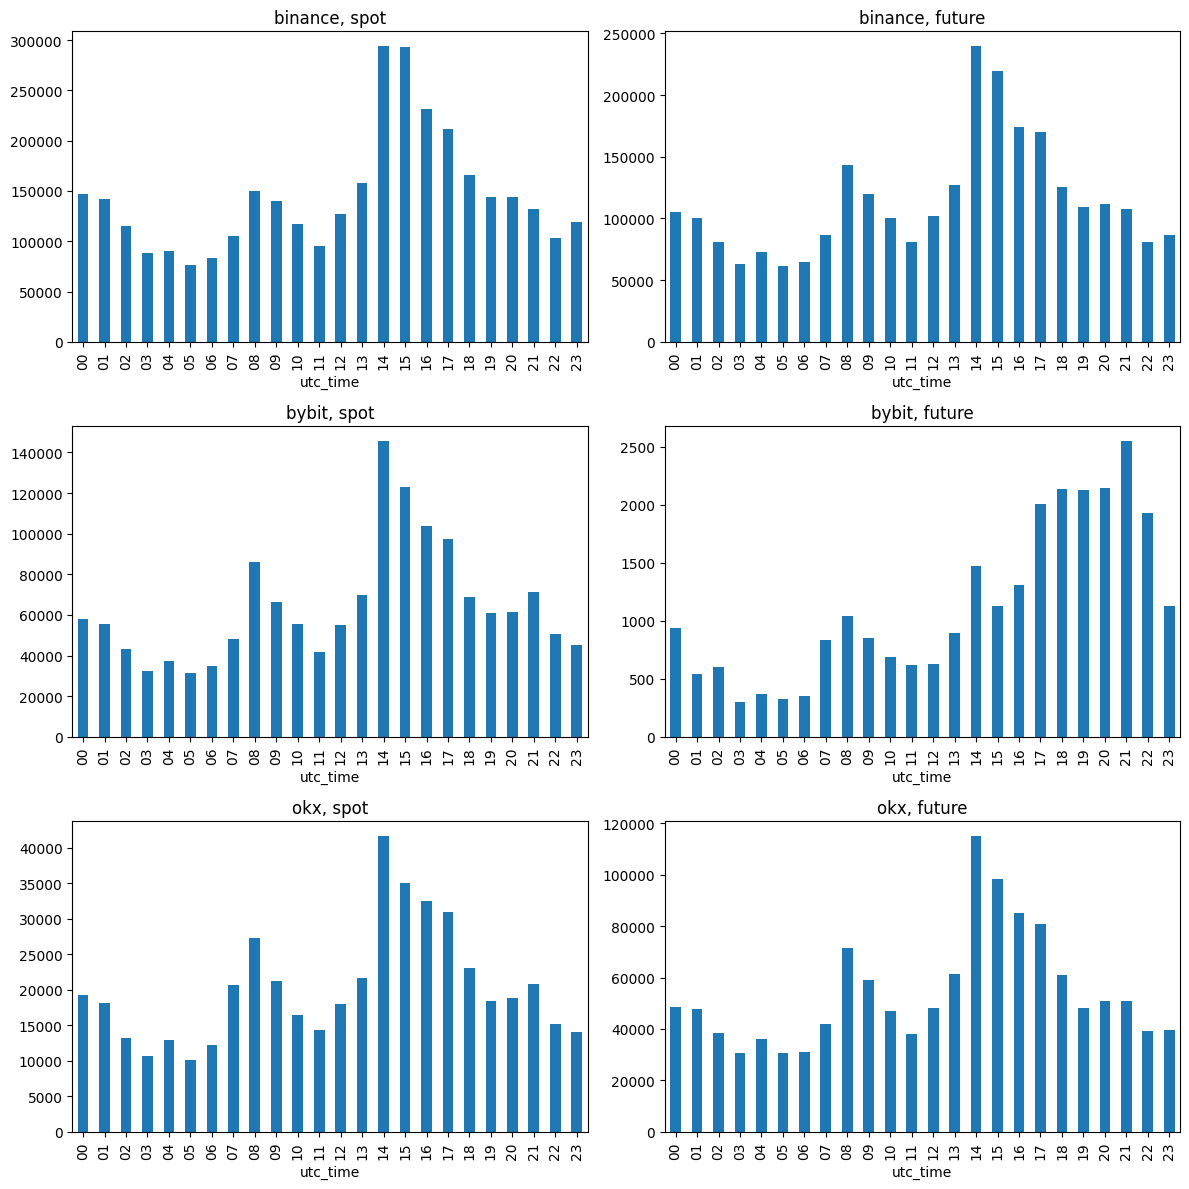

In [4]:
def draw_hourly_trade(df, **figargs):    
    hourly_df = df.groupby(df['utc_time'].dt.to_period("1h")).agg({'price': ['first', 'max', 'min', 'last'], 
                                                                   "qty": ['sum', 'count']})
    hourly_df.columns = ['open', 'high', 'low', 'close', 'volume', 'count']
    hourly_mean = hourly_df.groupby(hourly_df.index.strftime("%H"))['count'].mean()
    hourly_mean.plot(kind='bar', **figargs)

fig, ax = plt.subplots(3, 2, figsize=(12, 12))

i = 0
for exchange_name in ['binance', 'bybit', 'okx']:
    for market in ['spot', 'future']:
        draw_hourly_trade(tickdata[f"{exchange_name}_{market}"], title=f"{exchange_name}, {market}", ax=ax[i // 2][i % 2])    
        i += 1
            
plt.tight_layout()

In [6]:
def get_tick_data(df, grouper_time='utc_time'):
    df = df.copy()
    df['dolvol'] = df['price'] * df['qty']
    
    if grouper_time == 'utc_time':
        grouper = df['utc_time']
    elif grouper_time == 'time':
        grouper = df['time']
    else:
        raise ValueError()
    
    adjusted = df.groupby(grouper)[['dolvol', 'qty']].agg({"dolvol": 'sum', 'qty': 'sum'})
    adjusted = adjusted.reset_index()
    adjusted['price'] = adjusted['dolvol'] / adjusted['qty']
    adjusted['log_price'] = np.log(adjusted['price'])
    adjusted['return'] = adjusted['log_price'].diff()
    adjusted['prev_time'] = adjusted[grouper_time].shift(1)
    return adjusted[[grouper_time, 'price', 'log_price', 'return', 'prev_time']].copy()

tick_dict = {}
for key in tickdata.keys():
    tick_dict[key] = get_tick_data(tickdata[key], 'time')

In [ ]:
df1 = tick_dict['okx_spot'][['time', 'return']].set_index("time").copy()
df2 = tick_dict['okx_future'][['time', 'return']].set_index("time").copy()

# extreme_binance = tick_binance[tick_binance['return'] > 4 * 10**(-4)].copy()
# extreme_bybit = tick_bybit[tick_bybit['return'] > 4 * 10**(-4)].copy()

In [1]:
# Single Core Task
def hayashi_yoshida_estimator(df1, df2):
    # df1, df2 must have time(timestamp) and return columns 
    temp_df1 = df1.iloc[1:]['return']
    temp_df2 = df2.iloc[1:]['return']
    
    # Make interval
    I1 = pd.IntervalIndex.from_arrays(df1.index[:-1], df1.index[1:])
    I2 = pd.IntervalIndex.from_arrays(df2.index[:-1], df2.index[1:])

    # Calculate covariances
    hy_cov = 0
    minarg = 0
    for i2 in I2:
        # for each interval of df2
        
        found = False
        for i in range(minarg, len(I1)):
            # for each interval from previous interval's end
            
            if (I1[i].left < i2.right) and (I1[i].right > i2.left):
                # if overlap two intervals.
                # calculate covariance
                hy_cov += temp_df1.loc[I1[i].right] * temp_df2.loc[i2.right]
                
                # set params for next iter.
                found = True
                minarg = i

            elif I1[i].left > i2.right:
                # overlap is not init. (at the Begining)
                break
            elif I1[len(I1) - 1].right <= i2.left:
                # overlap is not init (at the End)
                break
            elif found:
                # if overlap series is ended.
                break
        
    # calculate HY estimator    
    hy_corr = hy_cov / np.sqrt(np.sum(temp_df1 ** 2) * np.sum(temp_df2 ** 2))
    return hy_corr

In [6]:
from concurrent.futures import ProcessPoolExecutor

# Multi Core Task
def main_work(df1, df2, n_workers=3):
    # df1, df2 must have time(timestamp) and return columns 
    temp_df1 = df1.iloc[1:]['return']
    temp_df2 = df2.iloc[1:]['return']

    I1 = pd.IntervalIndex.from_arrays(df1.index[:-1], df1.index[1:])
    I2 = pd.IntervalIndex.from_arrays(df2.index[:-1], df2.index[1:])
    
    temp_df1.index = I1
    temp_df2.index = I2
    
    # multi-threading or multi-processing
    # TO-DO: Divide works (estimate_task) to <n_workers> workers
    #        and save results in hycov_list for each workers.
    
    # Split intervals of df2 into n_workers
    delta = len(I2) / 3
    split_idx = [int(delta * i) for i in range(3+1)]
    split_intervals = [I2[split_idx[i]:split_idx[i+1]] for i in range(3)]
    results = []
    
    with ProcessPoolExecutor(max_workers=n_workers) as executor:
        futures = [
            executor.submit(estimate_task, temp_df1, temp_df2.loc[split])
            for split in split_intervals
        ]
        for future in futures:
            results.append(future.result())
    
    hy_cov = np.sum(results)
    hy_corr = hy_cov / (np.sqrt(np.sum(temp_df1 ** 2) * np.sum(temp_df2 ** 2)))
    return hy_corr

def estimate_task(df1, df2):
    # df1, df2 must have IntervalIndex and return columns
    I1 = df1.index
    I2 = df2.index
    
    # Calculate covariances
    hy_cov = 0
    minarg = 0
    for i2 in I2:
        # for each interval of df2
        
        found = False
        for i in range(minarg, len(I1)):
            # for each interval from previous interval's end
            
            if (I1[i].left < i2.right) and (I1[i].right > i2.left):
                # if overlap two intervals.
                # calculate covariance
                hy_cov += df1.loc[I1[i]] * df2.loc[i2]
                
                # set params for next iter.
                found = True
                minarg = i

            elif I1[i].left > i2.right:
                # overlap is not init. (at the Begining)
                break
            elif I1[len(I1) - 1].right <= i2.left:
                # overlap is not init (at the End)
                break
            elif found:
                # if overlap series is ended.
                break
        
    # calculate HY estimator    
    return hy_cov

In [7]:
okx_spot = tickdata.fetch_okx("2024-12-25", "2025-01-04", 'spot')
okx_future = tickdata.fetch_okx("2024-12-25", "2025-01-04", 'future')

okx_spot_tick = get_tick_data(okx_spot, 'time')
okx_future_tick = get_tick_data(okx_future, 'time')

df1 = okx_spot_tick[['time', 'return']].set_index("time").copy()
df2 = okx_future_tick[['time', 'return']].set_index("time").copy()

In [19]:
# corr w.r.t. hour

# hr_hour_binance = tick_binance[tick_binance['utc_time'].dt.hour.isin([22, 23])].copy()
# hr_hour_bybit = tick_bybit[tick_bybit['utc_time'].dt.hour.isin([22, 23])].copy()

# us_open_binance = tick_binance[tick_binance['utc_time'].dt.hour.isin([14,15,16,17,18,19])].copy()
# us_open_bybit = tick_bybit[tick_bybit['utc_time'].dt.hour.isin([14,15,16,17,18,19])].copy()

<Axes: xlabel='lag'>

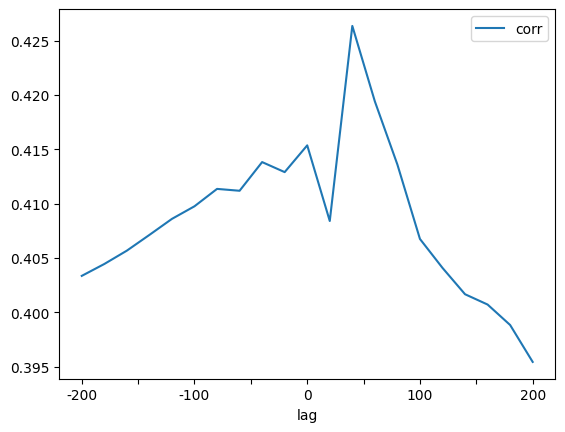

In [176]:
eb_corr = r"C:\Users\wklee\Desktop\WKLee\FBA\Capstone\fba-capstone\data\HY_CORR_binance-future-ETHBTC-artf_okx-spot-ETH-BTC_2024-12-25-2025-01-05.txt"

df = read_txt(eb_corr)
# with open(eb_corr) as f:

df.plot()